# 04 · Spatial immune phenotypes in hot tumours

**Aim:** to describe how the spatial organisation of lymphocytes (inflamed vs excluded) relates to the molecular profile of the tumour.

The image defines the groups and the molecular data explain them:

1. **Calibration:** do OpenTME image features agree with independent molecular measurements?
2. **Choice of the phenotype definition:** whole-slide (carcinoma vs stroma) or tumour-anchored (tumour core vs invasive margin) lymphocyte densities?
3. **Cold vs hot:** select tumours with enough immune infiltrate (leukocyte fraction ≥ cohort median).
4. **Spatial phenotype:** within hot tumours, classify each tumour as *inflamed* or *excluded* with the infiltration index, log10(core / outer margin).
5. **Pre-specified hypotheses:** five mechanisms of immune exclusion, tested on molecular variables (forest plot).
6. **Subtype consistency:** the same comparison within each molecular subtype (heatmap).
7. **Unbiased screen:** all molecular variables (volcano plot).
8. **Clinical outcome (exploratory):** survival and surgical margin status by phenotype.
9. **Export** of the patient-level phenotype table.

**Statistical model (sections 5–7):** `outcome ~ phenotype + C(subtype) + purity`, OLS with HC3 robust standard errors on a standardised outcome, so the effect is the difference inflamed − excluded in SD units. Binary outcomes use logistic regression (log2 odds ratio). Multiple testing is controlled with Benjamini-Hochberg FDR.

Column names, thresholds and hypotheses are in `configs/analysis.yaml` (section `immune_phenotypes`); indication-specific choices (subtype columns of the heatmap, extra strata such as TNBC, genes in the Cox models) are in the indication file. Statistical helpers are in `src/opentme_tcga/stats.py`, phenotype definitions in `src/opentme_tcga/phenotypes.py`. The *Observations* describe the results of the pilot indication (breast cancer).

**Outputs**: tables in `results/<indication>/04_immune_phenotypes/` and figures in `figures/<indication>/04_immune_phenotypes/`; the patient-level phenotype table in `<data>/processed/spatial_phenotypes_<opentme>.parquet` (input of notebook 05).

## 0. Setup

In [1]:
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test
from matplotlib.lines import Line2D
from scipy.stats import chi2_contingency, skew

from opentme_tcga import phenotypes as ph
from opentme_tcga import stats
from opentme_tcga.config import ensure_dirs, load_config
from opentme_tcga.opentme import get_thumbnail
from opentme_tcga.plotting import HOT_COLD_COLORS, MEDIAN_RULE_COLORS, PHENOTYPE_COLORS, TLS_GROUP_COLORS
from opentme_tcga.stats import add_fdr, assign_family, spearman_ci, zscore
from opentme_tcga.tcga import figure_label, load_labels, make_label

INDICATION = "breast"          # name of a file in configs/indications/

cfg = load_config(INDICATION)
P = cfg["paths"]
IP = cfg["immune_phenotypes"]
SUB = cfg["tcga_molecular"]["subtypes"]

OUT_DIR = P["results"] / "04_immune_phenotypes"
FIGS, TABLES = P["figures"] / "04_immune_phenotypes", OUT_DIR    # figures | tables
ensure_dirs(cfg)
FIGS.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(P["integrated"])
print(f"Integrated cohort: {df.shape[0]} patients, {df.shape[1]} columns")

Integrated cohort: 1025 patients, 756 columns


## 1. Configuration

Column names, thresholds and colours come from the configuration; here they only get short names. Every model below compares inflamed (1) with excluded (0) tumours with the same covariates.

In [2]:
IMG, CL = IP["image"], IP["clinical"]
LYMPH_TOTAL, TUMOR_CELL_FRACTION = IMG["lymphocyte_density"]["feature"], IMG["tumour_cell_fraction"]["feature"]
LYMPH_CORE, LYMPH_MARGIN = IMG["lymphocytes_core"]["feature"], IMG["lymphocytes_margin"]["feature"]
LYMPH_CARCINOMA, LYMPH_STROMA = IMG["lymphocytes_carcinoma"]["feature"], IMG["lymphocytes_stroma"]["feature"]
LEUKOCYTE_FRACTION, PURITY, TIL_SALTZ = (IP["molecular"][k] for k in ("leukocyte_fraction", "purity", "til_saltz"))
AGE, STAGE, MARGIN_STATUS = CL["age"], CL["stage"], CL["margin_status"]
PFI, PFI_TIME, OS, OS_TIME = CL["pfi"], CL["pfi_time"], CL["os"], CL["os_time"]
SUBTYPE, SUBTYPE_LABEL = SUB["column"], SUB["label"]
SUBTYPE_ORDER = [s for s in SUB.get("order") or df[SUBTYPE].value_counts().index if s in set(df[SUBTYPE].dropna())]
HOT_QUANTILE, INDEX_THRESHOLD, EPS = IP["hot_quantile"], IP["index_threshold"], IP["eps"]
MIN_PER_GROUP, MIN_SUBTYPE_LEVEL, FDR_ALPHA = IP["min_per_group"], IP["min_subtype_level"], IP["fdr_alpha"]

COLOR_INFLAMED, COLOR_EXCLUDED = PHENOTYPE_COLORS["Inflamed"], PHENOTYPE_COLORS["Excluded"]
COLOR_COLD, COLOR_HOT = HOT_COLD_COLORS["Cold"], HOT_COLD_COLORS["Hot"]
plt.rcdefaults()
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "figure.titlesize": 13})

# Densities in cells/mm² (<feature>_MM2), with the unit factor of their OpenTME table
df = ph.add_densities_mm2(df, IMG, cfg["density_per_mm2"])

# Readable names and the two models, bound to this analysis (exposure and covariates)
LABELS = load_labels(P["configs"] / "variable_labels.yaml")
pretty_label = lambda col: make_label(col, LABELS) or col
clean_label = lambda col: figure_label(col, LABELS)
fit_effect = partial(stats.fit_effect, exposure="phenotype_binary", min_per_group=MIN_PER_GROUP)
fit_logit = partial(stats.fit_logit, exposure="phenotype_binary", categorical=[SUBTYPE], continuous=[PURITY],
                    min_level=MIN_SUBTYPE_LEVEL)

## 2. Calibration: image features vs. molecular measurements

The H&E slide and the sequenced tissue come from different pieces of the same tumour, so agreement between them has a ceiling set by intratumour heterogeneity. We compare:

1. OpenTME tumour-cell fraction vs. ABSOLUTE DNA purity.
2. OpenTME lymphocyte density vs. DNA-methylation leukocyte fraction.
3. OpenTME lymphocyte density vs. Saltz et al. TIL fraction (deep learning on the same TCGA slides).
4. ABSOLUTE purity vs. leukocyte fraction (molecular vs. molecular reference).

First, the distributions and their skewness, which decide whether a variable is shown on a log scale.

In [3]:
df["img_lymph_total_mm2"] = df[f"{LYMPH_TOTAL}_MM2"]

features_to_inspect = [
    (TUMOR_CELL_FRACTION, "Tumour-cell fraction (OpenTME)"),
    (PURITY, "Tumour purity (ABSOLUTE, DNA)"),
    ("img_lymph_total_mm2", "Lymphocyte density (OpenTME)"),
    (LEUKOCYTE_FRACTION, "Leukocyte fraction (DNA methylation)"),
    (TIL_SALTZ, "TIL fraction (Saltz et al.)"),
]
skew_df = pd.DataFrame([
    {"Feature": label, "n": df[col].notna().sum(), "Mean": df[col].mean(),
     "Median": df[col].median(), "Skewness": skew(df[col].dropna())}
    for col, label in features_to_inspect if col in df.columns
])
display(skew_df.round(3))

,Feature,n,Mean,Median,Skewness
0,Tumour-cell fraction (OpenTME),1025,42.345,42.500,0.093
1,"Tumour purity (ABSOLUTE, DNA)",957,0.586,0.590,-0.171
2,Lymphocyte density (OpenTME),1025,451.849,291.800,2.826
3,Leukocyte fraction (DNA methylation),998,0.216,0.180,1.340
4,TIL fraction (Saltz et al.),916,3.704,1.322,2.651


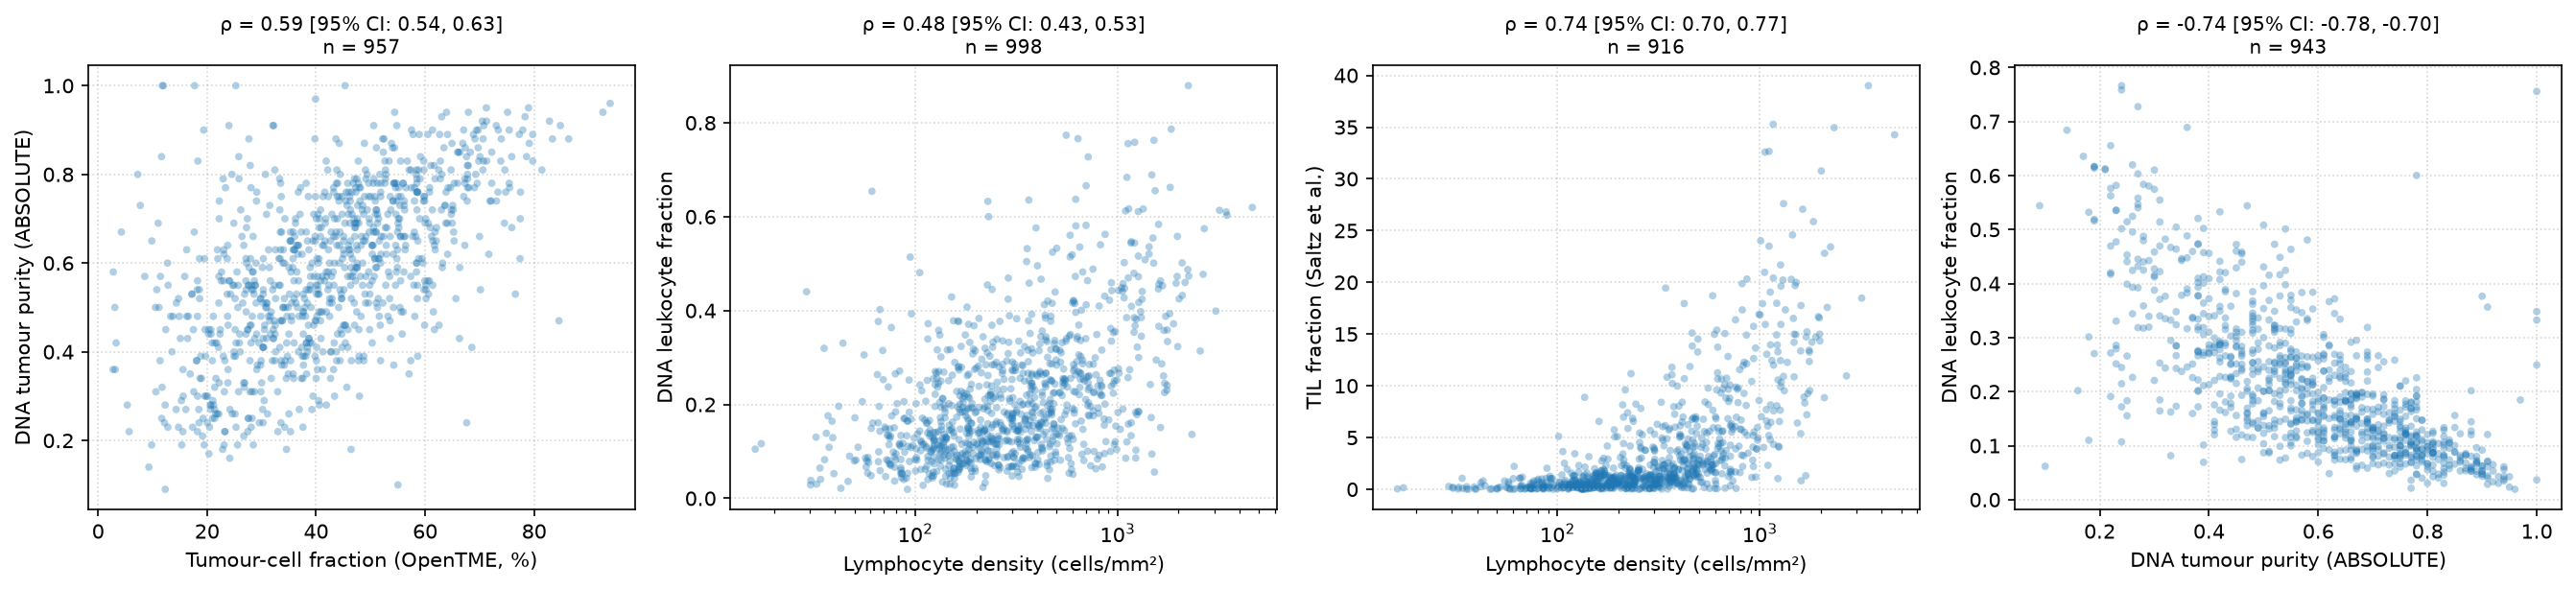

In [4]:
calib_pairs = [
    (TUMOR_CELL_FRACTION, PURITY, "Tumour-cell fraction (OpenTME, %)", "DNA tumour purity (ABSOLUTE)", False),
    ("img_lymph_total_mm2", LEUKOCYTE_FRACTION, "Lymphocyte density (cells/mm²)", "DNA leukocyte fraction", True),
    ("img_lymph_total_mm2", TIL_SALTZ, "Lymphocyte density (cells/mm²)", "TIL fraction (Saltz et al.)", True),
    (PURITY, LEUKOCYTE_FRACTION, "DNA tumour purity (ABSOLUTE)", "DNA leukocyte fraction", False),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), dpi=150)
for ax, (xcol, ycol, xlabel, ylabel, logx) in zip(axes, calib_pairs):
    if xcol not in df.columns or ycol not in df.columns:
        ax.set_visible(False)
        continue
    sub = df[[xcol, ycol]].dropna()
    if logx:
        sub = sub[sub[xcol] > 0]
        ax.set_xscale("log")
    rho, low, high, n = spearman_ci(sub[xcol], sub[ycol])
    ax.scatter(sub[xcol], sub[ycol], alpha=0.35, s=14, color="#1f77b4", edgecolors="none")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"ρ = {rho:.2f} [95% CI: {low:.2f}, {high:.2f}]\nn = {n}", fontsize=9.5)
    ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
fig.savefig(FIGS / "fig1_cross_modal_calibration.png", bbox_inches="tight", dpi=300)
plt.show()

**Observations (breast)**
- Image and molecular estimates agree moderately, within the ceiling set by intratumour heterogeneity (the slide and the sequenced tissue are different pieces of the tumour).
- Lymphocyte density is right-skewed and is shown on a log scale.

## 3. Choice of the phenotype definition

Two ways to describe where lymphocytes are, each split at the cohort median as in TME Studio (inflamed if the inside density is above its median, otherwise excluded if the outside density is above its median, otherwise desert):

1. **Whole slide:** lymphocytes in carcinoma vs in all stroma of the slide.
2. **Tumour-anchored (whole tumour region):** lymphocytes in the tumour core vs in the outer invasive margin (1 mm outside the tumour border).

We compare their agreement and their association with mature TLS, an independent marker of an organised immune response. This section uses all tumours; the analysis itself (sections 4–5) uses the tumour-anchored densities in hot tumours, as a continuous index rather than median splits.

In [5]:
rules = pd.DataFrame({
    "whole_slide": ph.median_rule(df[f"{LYMPH_CARCINOMA}_MM2"], df[f"{LYMPH_STROMA}_MM2"]),
    "tumour_anchored": ph.median_rule(df[f"{LYMPH_CORE}_MM2"], df[f"{LYMPH_MARGIN}_MM2"]),
})
classes = list(MEDIAN_RULE_COLORS)
both = rules.dropna()
print(f"Agreement between the two rules: {(both['whole_slide'] == both['tumour_anchored']).mean():.1%} of {len(both)} tumours")
print("Row %: whole-slide class (rows) reclassified by the tumour-anchored rule (columns)")
(pd.crosstab(both["whole_slide"], both["tumour_anchored"], normalize="index") * 100).reindex(
    index=classes, columns=classes).round(1)

Agreement between the two rules: 66.2% of 1025 tumours
Row %: whole-slide class (rows) reclassified by the tumour-anchored rule (columns)


tumour_anchored,inflamed,excluded,desert
whole_slide,,,
inflamed,74.4,8.0,17.6
excluded,61.2,32.9,5.9
desert,7.9,21.6,70.6


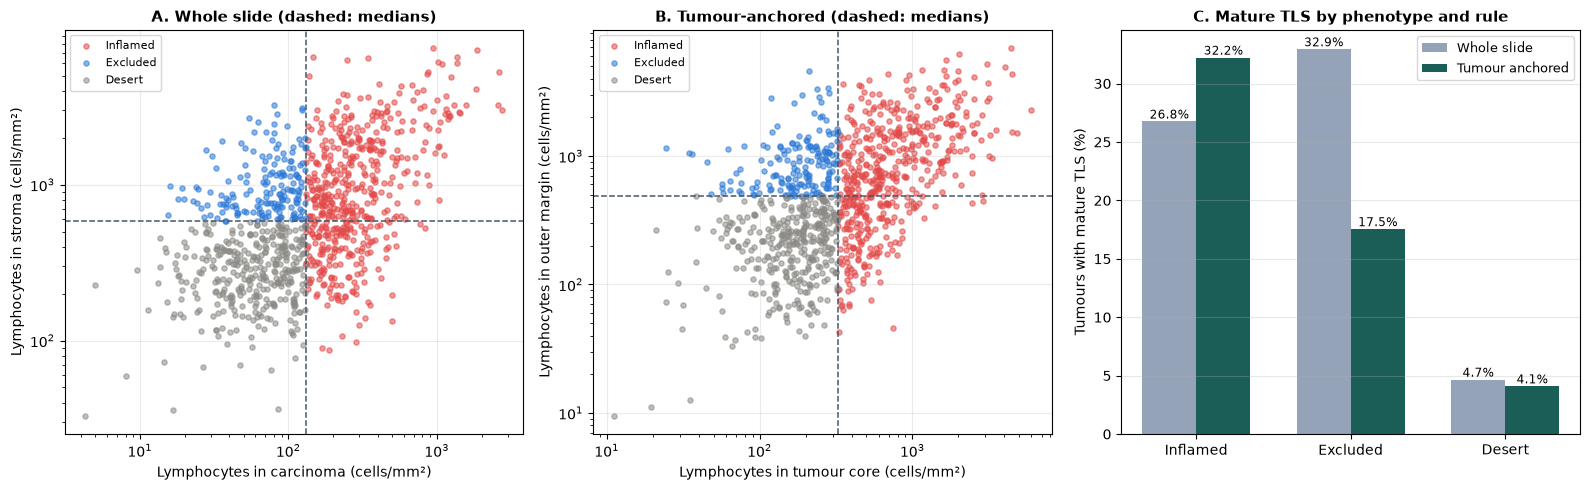

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
panels = [("whole_slide", LYMPH_CARCINOMA, LYMPH_STROMA, "carcinoma", "stroma", "A. Whole slide"),
          ("tumour_anchored", LYMPH_CORE, LYMPH_MARGIN, "tumour core", "outer margin", "B. Tumour-anchored")]
for ax, (rule, inside, outside, in_name, out_name, title) in zip(axes, panels):
    x, y = df[f"{inside}_MM2"], df[f"{outside}_MM2"]
    for name, color in MEDIAN_RULE_COLORS.items():
        m = (rules[rule] == name) & (x > 0) & (y > 0)
        ax.scatter(x[m], y[m], s=14, alpha=0.55, color=color, label=name.capitalize())
    ax.axvline(x.median(), color="#475569", ls="--", lw=1.1)
    ax.axhline(y.median(), color="#475569", ls="--", lw=1.1)
    ax.set(xscale="log", yscale="log", xlabel=f"Lymphocytes in {in_name} (cells/mm²)",
           ylabel=f"Lymphocytes in {out_name} (cells/mm²)")
    ax.set_title(f"{title} (dashed: medians)", fontweight="bold")
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.25)

ax = axes[2]
tls = pd.DataFrame({r: df.groupby(rules[r])["DERIVED_MATURE_TLS_PRESENT"].mean() * 100 for r in rules}).reindex(classes)
x = np.arange(len(classes))
for i, (r, color) in enumerate([("whole_slide", "#94a3b8"), ("tumour_anchored", TLS_GROUP_COLORS["Mature"])]):
    bars = ax.bar(x + (i - 0.5) * 0.35, tls[r], 0.35, color=color, label=r.replace("_", " ").capitalize())
    ax.bar_label(bars, fmt="%.1f%%", fontsize=8.5)
ax.set_xticks(x, [c.capitalize() for c in classes])
ax.set_ylabel("Tumours with mature TLS (%)")
ax.set_title("C. Mature TLS by phenotype and rule", fontweight="bold")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGS / "fig1b_phenotype_definition.png", bbox_inches="tight", dpi=300)
plt.show()

**Observations (breast)**
- Lymphocyte densities form a continuum without clusters, so any split is a convention. The analysis uses a threshold with a direct meaning (index = 0: equal density in tumour core and outer margin) rather than cohort medians, which depend on the cohort.
- The two rules agree in about two thirds of tumours, mostly for inflamed and desert tumours. Most whole-slide *excluded* tumours are *inflamed* with the tumour-anchored rule; a likely reason is that whole-slide stroma also contains lymphocytes far from the tumour (e.g. lymphoid aggregates, normal tissue), which the tumour-anchored rule ignores.
- Mature TLS are more frequent in whole-slide *excluded* than in *inflamed* tumours, but follow the opposite pattern with the tumour-anchored rule. This is consistent with stromal lymphoid aggregates inflating whole-slide stromal densities, although it is not an independent validation, since TLS are themselves lymphocyte aggregates.
- The analysis uses tumour core vs outer invasive margin because immune exclusion is defined relative to the tumour border, which the whole tumour region delineates; the comparison above shows that the choice matters.

## 4. Cold vs. hot tumours

The inflamed/excluded question only makes sense in tumours with enough lymphocytes. Hot tumours are those with DNA-methylation leukocyte fraction ≥ the cohort median; this keeps half of the cohort (more statistical power) while removing immune-poor tumours. The second panel shows how the SUBTYPE subtypes are distributed between cold and hot tumours.

In [7]:
df["is_hot"], hot_threshold = ph.hot_flag(df[LEUKOCYTE_FRACTION], HOT_QUANTILE)
print(f"Leukocyte fraction threshold: {hot_threshold:.3f}")
print(f"Hot: {(df['is_hot'] == 1).sum()} | Cold: {(df['is_hot'] == 0).sum()} | Missing: {df['is_hot'].isna().sum()}")

Leukocyte fraction threshold: 0.180
Hot: 499 | Cold: 499 | Missing: 27


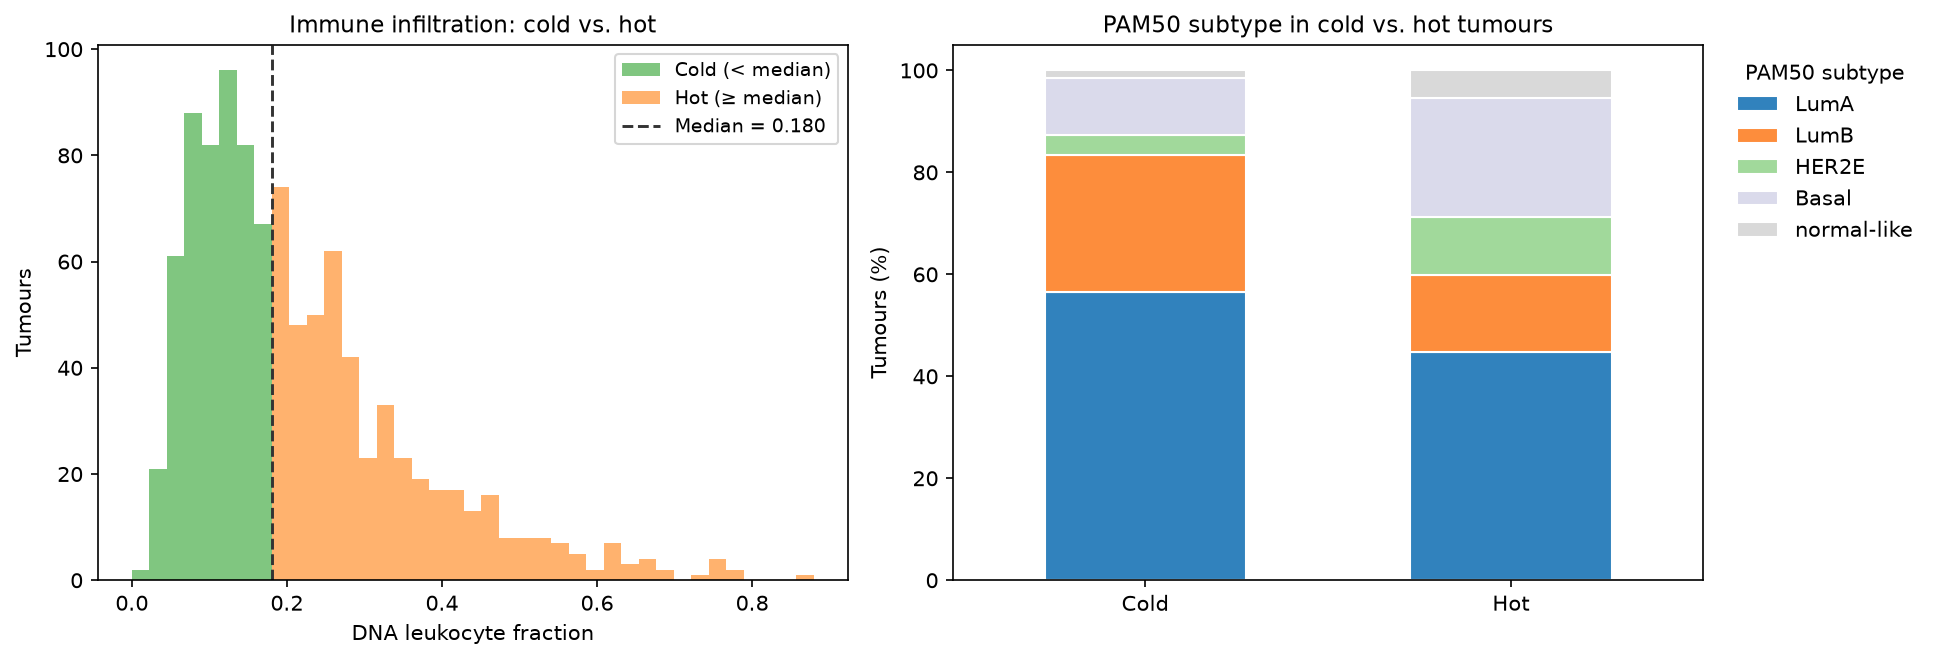

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=150)

# A: leukocyte fraction distribution with the threshold
lf = df[LEUKOCYTE_FRACTION].dropna()
bins = np.linspace(0, lf.max(), 40)
ax1.hist(lf[lf < hot_threshold], bins=bins, color=COLOR_COLD, alpha=0.6, label="Cold (< median)")
ax1.hist(lf[lf >= hot_threshold], bins=bins, color=COLOR_HOT, alpha=0.6, label="Hot (≥ median)")
ax1.axvline(hot_threshold, color="#333333", linestyle="--", lw=1.4, label=f"Median = {hot_threshold:.3f}")
ax1.set_xlabel("DNA leukocyte fraction")
ax1.set_ylabel("Tumours")
ax1.set_title("Immune infiltration: cold vs. hot")
ax1.legend(fontsize=9)

# B: SUBTYPE composition of cold and hot tumours
sub = df[[SUBTYPE, "is_hot"]].dropna()
ct = (pd.crosstab(sub[SUBTYPE], sub["is_hot"].map({0.0: "Cold", 1.0: "Hot"}), normalize="columns") * 100).reindex([s for s in SUBTYPE_ORDER if s in set(sub[SUBTYPE])])
ct.T.plot(kind="bar", stacked=True, ax=ax2, colormap="tab20c", edgecolor="white", width=0.55)
ax2.set_ylabel("Tumours (%)")
ax2.set_xlabel("")
ax2.set_title(f"{SUBTYPE_LABEL} in cold vs. hot tumours")
ax2.legend(title=f"{SUBTYPE_LABEL}", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax2.tick_params(axis="x", rotation=0)

plt.tight_layout()
fig.savefig(FIGS / "fig2a_cold_vs_hot.png", bbox_inches="tight", dpi=300)
plt.show()

## 5. Spatial phenotype within hot tumours

**Infiltration index** = log10((density in tumour core + ε) / (density in outer invasive margin + ε)), with densities in cells/mm².

- **Inflamed** (index ≥ 0): at least as many lymphocytes inside the tumour as at its outer margin.
- **Excluded** (index < 0): lymphocytes concentrate at the outer margin.

The index measures *where* the lymphocytes are, independently of *how many* there are (the amount is already fixed by selecting hot tumours). Coding for the models: inflamed = 1, excluded = 0, so a positive effect means "higher in inflamed".

In [9]:
df["spatial_index_wtr"] = ph.infiltration_index(df[f"{LYMPH_CORE}_MM2"], df[f"{LYMPH_MARGIN}_MM2"], EPS)
df["spatial_phenotype"] = ph.spatial_phenotype(df["is_hot"], df["spatial_index_wtr"], INDEX_THRESHOLD)
df["phenotype_binary"] = df["spatial_phenotype"].map({"Inflamed": 1.0, "Excluded": 0.0})
is_hot = df["is_hot"] == 1
hot = df[is_hot].copy()
print(df["spatial_phenotype"].value_counts(dropna=False))

print(f"\nPhenotype by {SUBTYPE_LABEL}, hot tumours (row %):")
display((pd.crosstab(hot[SUBTYPE], hot["spatial_phenotype"], normalize="index") * 100).round(1))

spatial_phenotype
Cold        499
Excluded    292
Inflamed    207
None         27
Name: count, dtype: int64

Phenotype by PAM50 subtype, hot tumours (row %):


spatial_phenotype,Excluded,Inflamed
clin_pam50,,
Basal,75.9,24.1
HER2E,71.9,28.1
LumA,45.7,54.3
LumB,67.1,32.9
normal-like,37.0,63.0


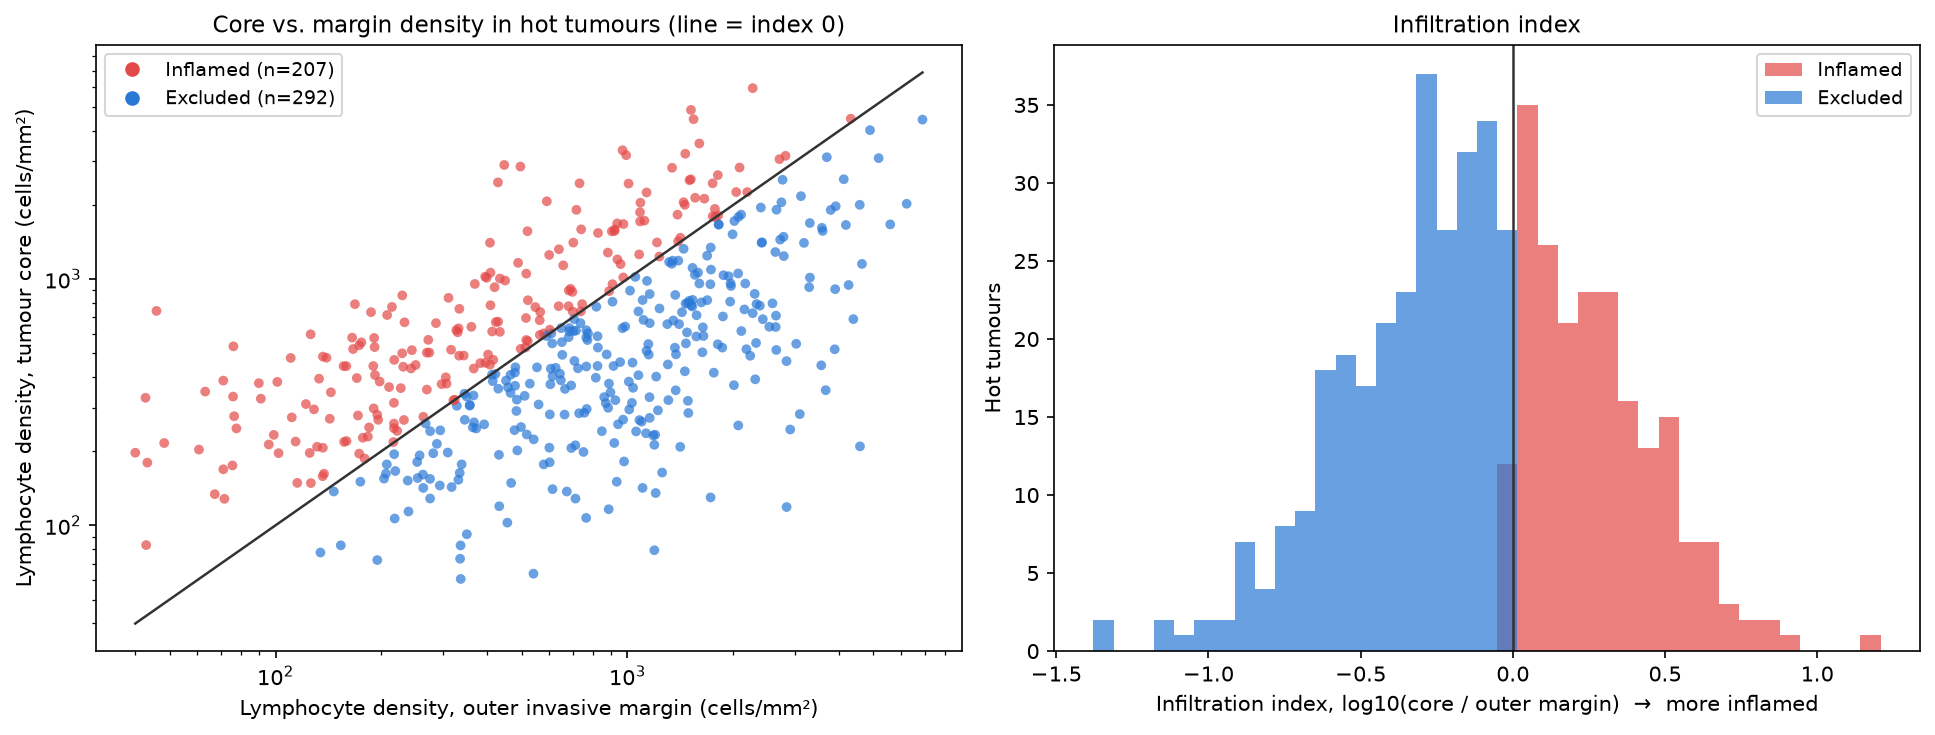

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
d = hot.dropna(subset=["spatial_phenotype"]).copy()
d["core_mm2"], d["margin_mm2"] = d[f"{LYMPH_CORE}_MM2"], d[f"{LYMPH_MARGIN}_MM2"]
d = d[(d["core_mm2"] > 0) & (d["margin_mm2"] > 0)]

# A: core vs. margin density; the 1:1 line is the classification threshold (index = 0)
ax1.scatter(d["margin_mm2"], d["core_mm2"], c=d["spatial_phenotype"].map(PHENOTYPE_COLORS),
            s=22, alpha=0.7, edgecolors="none")
lims = [min(d["margin_mm2"].min(), d["core_mm2"].min()), max(d["margin_mm2"].max(), d["core_mm2"].max())]
ax1.plot(lims, lims, color="#333333", lw=1.2)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("Lymphocyte density, outer invasive margin (cells/mm²)")
ax1.set_ylabel("Lymphocyte density, tumour core (cells/mm²)")
ax1.set_title("Core vs. margin density in hot tumours (line = index 0)")
ax1.legend(handles=[Line2D([0], [0], marker="o", lw=0, color=c, label=f"{k} (n={(d['spatial_phenotype'] == k).sum()})")
                    for k, c in PHENOTYPE_COLORS.items()], fontsize=9, loc="upper left")

# B: distribution of the infiltration index
bins = np.linspace(d["spatial_index_wtr"].min(), d["spatial_index_wtr"].max(), 40)
for k, c in PHENOTYPE_COLORS.items():
    ax2.hist(d.loc[d["spatial_phenotype"] == k, "spatial_index_wtr"], bins=bins, color=c, alpha=0.7, label=k)
ax2.axvline(INDEX_THRESHOLD, color="#333333", lw=1.2)
ax2.set_xlabel("Infiltration index, log10(core / outer margin)  →  more inflamed")
ax2.set_ylabel("Hot tumours")
ax2.set_title("Infiltration index")
ax2.legend(fontsize=9)

plt.tight_layout()
fig.savefig(FIGS / "fig2b_spatial_phenotypes.png", bbox_inches="tight", dpi=300)
plt.show()

### 5.1 Two example tumours

One inflamed and one excluded tumour (`example_tumours` in the indication file), highlighted on the core vs. margin scatter, next to an OpenTME thumbnail of their slide (layer set by `thumbnail_kind`; default: cell classification). Thumbnails come from OpenTME and are downloaded once into `<data>/raw/opentme/` (requires `hf auth login`).

In [ ]:
EXAMPLES = IP["example_tumours"]   # phenotype -> TCGA case ID
d = hot.dropna(subset=["spatial_phenotype"]).copy()
d["core_mm2"], d["margin_mm2"] = d[f"{LYMPH_CORE}_MM2"], d[f"{LYMPH_MARGIN}_MM2"]
d = d[(d["core_mm2"] > 0) & (d["margin_mm2"] > 0)]
examples = {pheno: d[d["patient"] == pid].iloc[0] for pheno, pid in EXAMPLES.items() if (d["patient"] == pid).any()}
missing = set(EXAMPLES) - set(examples)
if missing:
    print(f"Example tumours not found among hot tumours: {sorted(missing)}")


def thumbnail_keys(row):
    # Slide UUID and file name identify the analysed slide; the case ID is the fallback
    file_name = row.get("TCGA_FILE_NAME")
    return [row.get("TCGA_SLIDE_UUID"), Path(file_name).stem if isinstance(file_name, str) else None, row["patient"]]


if examples:
    fig, axes = plt.subplots(1, 1 + len(examples), figsize=(6 * (1 + len(examples)), 6), dpi=150,
                             gridspec_kw={"width_ratios": [1.15] + [1] * len(examples)})
    ax = axes[0]
    ax.scatter(d["margin_mm2"], d["core_mm2"], c=d["spatial_phenotype"].map(PHENOTYPE_COLORS),
               s=22, alpha=0.5, edgecolors="none", zorder=2)
    lims = [min(d["margin_mm2"].min(), d["core_mm2"].min()), max(d["margin_mm2"].max(), d["core_mm2"].max())]
    ax.plot(lims, lims, color="#333333", lw=1.2, ls="--", zorder=3)
    for pheno, r in examples.items():
        ax.scatter(r["margin_mm2"], r["core_mm2"], s=150, facecolor=PHENOTYPE_COLORS[pheno], edgecolor="black",
                   lw=1.8, zorder=5)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Lymphocyte density, outer invasive margin (cells/mm²)")
    ax.set_ylabel("Lymphocyte density, tumour core (cells/mm²)")
    ax.set_title("Core vs. margin density in hot tumours (line = index 0)")
    ax.legend(handles=[Line2D([0], [0], marker="o", lw=0, color=c, label=f"{k} (n={(d['spatial_phenotype'] == k).sum()})")
                       for k, c in PHENOTYPE_COLORS.items()], fontsize=9, loc="lower right", frameon=True,
              facecolor="white", framealpha=0.9, edgecolor="#cccccc")

    for ax, (pheno, r) in zip(axes[1:], examples.items()):
        color = PHENOTYPE_COLORS[pheno]
        path = get_thumbnail(P["raw_opentme"], cfg["opentme"]["repo_id"], thumbnail_keys(r), kind=IP["thumbnail_kind"],
                             revision=cfg["opentme"].get("revision"))
        if path is None:
            ax.text(0.5, 0.5, "Thumbnail not found", ha="center", va="center", transform=ax.transAxes)
        else:
            ax.imshow(plt.imread(path))
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color(color)
            spine.set_linewidth(2.5)
        ax.set_title(f"{pheno}: {r['patient']}\n{SUBTYPE_LABEL}: {r[SUBTYPE]}  |  infiltration index {r['spatial_index_wtr']:+.2f}\n"
                     f"core {r['core_mm2']:.0f}  |  margin {r['margin_mm2']:.0f} cells/mm²",
                     fontsize=10.5, fontweight="bold", color=color, pad=10)
    fig.tight_layout()
    fig.savefig(FIGS / "fig2c_example_tumours.png", bbox_inches="tight", dpi=300)
    plt.show()

## 6. Pre-specified hypotheses (forest plot)

Five general mechanisms of immune exclusion, with expected directions from Hammerl et al. 2021. Only molecular variables are used: the image defines the groups and is not used again as an outcome.

| Hypothesis | Idea | Variables |
|---|---|---|
| Barrier | The stroma walls off T cells | TGF-β response, CAF signature, COL10A1 |
| Brakes | T cells arrive but are switched off | Checkpoint molecules, Tregs |
| Response quality | Weak or few killer T cells | IFN-γ response, effector cells, CD8+ T cells |
| Visibility | Too few antigens to be recognised | TMB (log1p), HRD, MHC class I |
| Hypoxia | Low oxygen repels T cells | Buffa hypoxia score, Hallmark glycolysis |

The hypotheses and their variables are in the configuration (`hypotheses`); variables missing from the table are skipped. Each variable is standardised across hot tumours and compared between phenotypes twice: unadjusted, and adjusted for SUBTYPE and purity (main model). FDR is computed within each specification.

In [12]:
HYPOTHESES = IP["hypotheses"]

if "thor_tmb" in hot.columns:
    hot["thor_tmb_log1p"] = np.log1p(hot["thor_tmb"].clip(lower=0))

# One flat list (group, column, label), keeping only variables present in the table
hyp_vars = [(g, col, pretty_label(col)) for g, cols in HYPOTHESES.items() for col in cols if col in hot.columns]
missing = [col for cols in HYPOTHESES.values() for col in cols if col not in hot.columns]
if missing:
    print("Not found in table:", missing)

# Standardise once across hot tumours, so all models (forest, heatmap) share the same scale
for _, col, _ in hyp_vars:
    hot[col] = zscore(hot[col].astype(float))

SPECS = {"Unadjusted": {}, "Main": {"categorical": [SUBTYPE], "continuous": [PURITY]}}
hyp_res_df = pd.DataFrame([
    {"hypothesis_group": g, "variable": col, "variable_label": label, "specification": spec,
     **fit_effect(hot, col, **kwargs)}
    for g, col, label in hyp_vars for spec, kwargs in SPECS.items()
])
hyp_res_df = add_fdr(hyp_res_df, by="specification")
hyp_res_df.to_csv(TABLES / "prespecified_hypotheses_regression_results.csv", index=False)

main = hyp_res_df[hyp_res_df["specification"] == "Main"].copy()
main["Effect [95% CI]"] = main.apply(lambda r: f"{r.effect:+.2f} [{r.ci_lower:+.2f}, {r.ci_upper:+.2f}]", axis=1)
main["FDR"] = main["fdr"].map(lambda q: "<0.001" if q < 0.001 else f"{q:.3f}")
display(main[["hypothesis_group", "variable_label", "Effect [95% CI]", "FDR", "n"]])

,hypothesis_group,variable_label,Effect [95% CI],FDR,n
1,Barrier,TGF-β response (Thorsson),"-0.11 [-0.29, +0.06]",0.337,473
3,Barrier,Cancer-associated fibroblasts (ssGSEA),"-0.14 [-0.31, +0.03]",0.198,473
5,Barrier,COL10A1 expression (RNA),"-0.31 [-0.48, -0.14]",0.004,473
7,Brakes,Checkpoint molecules (ssGSEA),"+0.07 [-0.10, +0.24]",0.476,473
9,Brakes,Tregs (CIBERSORT),"-0.03 [-0.22, +0.16]",0.781,473
11,Response quality,IFN-γ response (Thorsson),"-0.11 [-0.30, +0.07]",0.337,473
13,Response quality,Effector cells (ssGSEA),"+0.16 [-0.01, +0.33]",0.198,473
15,Response quality,CD8 T cells (CIBERSORT),"+0.21 [+0.01, +0.40]",0.169,473
17,Visibility,"Tumour mutation burden, log (Thorsson)","-0.07 [-0.26, +0.11]",0.476,471
19,Visibility,HRD score (Thorsson),"-0.08 [-0.24, +0.07]",0.363,473


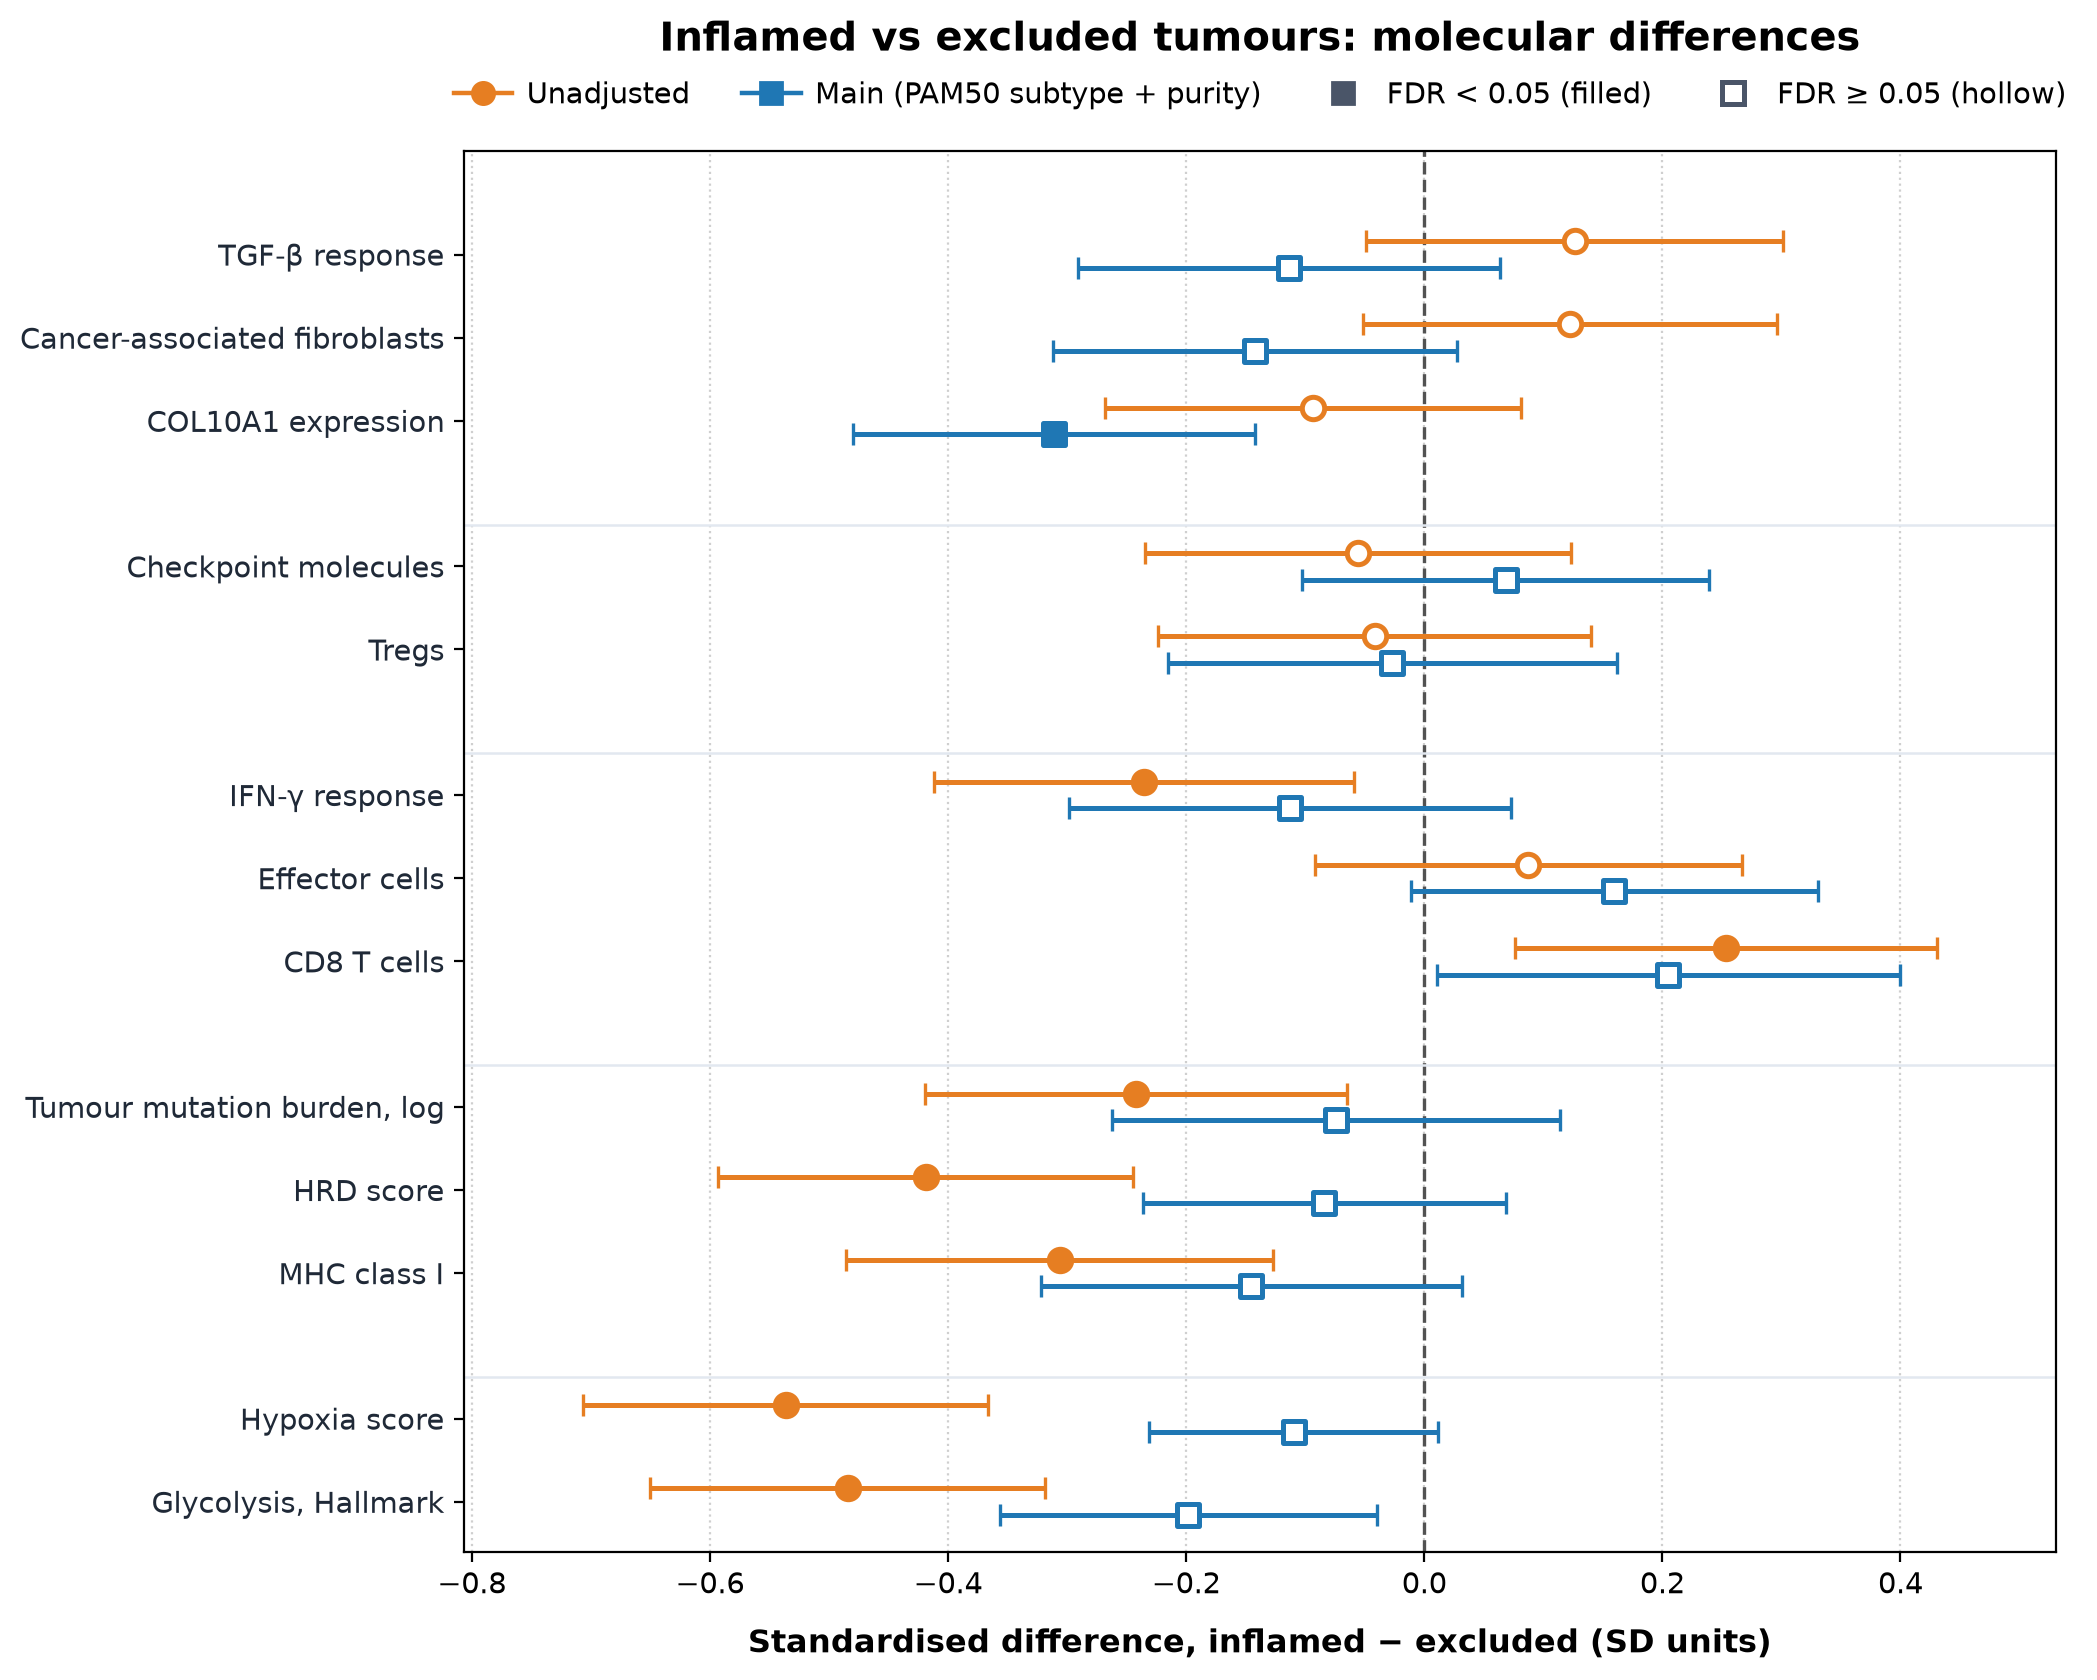

In [13]:
# Forest plot: one row per variable, grouped by hypothesis with a divider between groups
rows, div_lines, y = [], [], 0.0
for g in reversed(list(HYPOTHESES)):
    group_vars = [(col, label) for gg, col, label in hyp_vars if gg == g]
    if not group_vars:
        continue
    for col, label in reversed(group_vars):
        rows.append((y, col, label))
        y += 1.0
    div_lines.append(y - 0.5)
    y += 0.75

C_UNADJ, C_MAIN = "#e67e22", "#1f77b4"
fig, ax = plt.subplots(figsize=(10.5, 8.5), dpi=200)
ax.axvline(0, color="#525252", linestyle="--", lw=1.2)
for y_div in div_lines[:-1]:
    ax.axhline(y_div, color="#e2e8f0", lw=0.9)

for y_row, col, label in rows:
    for spec, color, marker, offset in [("Unadjusted", C_UNADJ, "o", 0.16), ("Main", C_MAIN, "s", -0.16)]:
        r = hyp_res_df[(hyp_res_df["variable"] == col) & (hyp_res_df["specification"] == spec)].iloc[0]
        if np.isnan(r["effect"]):
            continue
        ax.errorbar(r["effect"], y_row + offset, xerr=[[r["effect"] - r["ci_lower"]], [r["ci_upper"] - r["effect"]]],
                    fmt="none", ecolor=color, elinewidth=1.8, capsize=4, capthick=1.2)
        ax.scatter(r["effect"], y_row + offset, marker=marker, s=65, linewidths=1.8, zorder=4,
                   facecolors=color if r["fdr"] < FDR_ALPHA else "white", edgecolors=color)

ci = hyp_res_df[["ci_lower", "ci_upper"]].stack()
ax.set_xlim(min(ci.min(), 0) - 0.1, max(ci.max(), 0) + 0.1)
ax.set_yticks([r[0] for r in rows])
ax.set_yticklabels([clean_label(r[1]) for r in rows], fontsize=10.5, color="#1f2937")
ax.set_ylim(-0.6, y - 0.5)
ax.set_xlabel("Standardised difference, inflamed − excluded (SD units)", fontsize=11.5, fontweight="bold", labelpad=10)
ax.set_title("Inflamed vs excluded tumours: molecular differences", fontsize=14.5, fontweight="bold", pad=36)
ax.legend(handles=[
    Line2D([0], [0], marker="o", color=C_UNADJ, lw=1.6, markersize=8, label="Unadjusted"),
    Line2D([0], [0], marker="s", color=C_MAIN, lw=1.6, markersize=8, label=f"Main ({SUBTYPE_LABEL} + purity)"),
    Line2D([0], [0], marker="s", color="#4a5568", lw=0, markersize=8, label=f"FDR < {FDR_ALPHA} (filled)"),
    Line2D([0], [0], marker="s", color="#4a5568", lw=0, markerfacecolor="white", markeredgewidth=1.8, markersize=8,
           label=f"FDR ≥ {FDR_ALPHA} (hollow)"),
], loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=4, frameon=False, fontsize=10.5,
    handletextpad=0.5, columnspacing=1.8)
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.tick_params(axis="both", labelsize=10.5)
plt.tight_layout()
fig.savefig(FIGS / "fig3_forest_plot_prespecified_hypotheses.png", bbox_inches="tight", dpi=300)
plt.show()

## 7. Consistency across subtypes (heatmap)

Are the differences shared across subtypes? The same model is fitted in the whole hot cohort (adjusted for subtype + purity) and within each subtype with enough hot tumours (`subtype_strata` / `min_stratum_size`) and each extra stratum of the indication (breast: TNBC), adjusted for purity only. Variables keep the standardisation of section 6, so all columns are on the same scale. Power within subtypes is limited (minimum detectable effect ≈ 0.4–0.8 SD), so subtype columns are read for consistency of direction rather than significance. FDR is computed within each column.

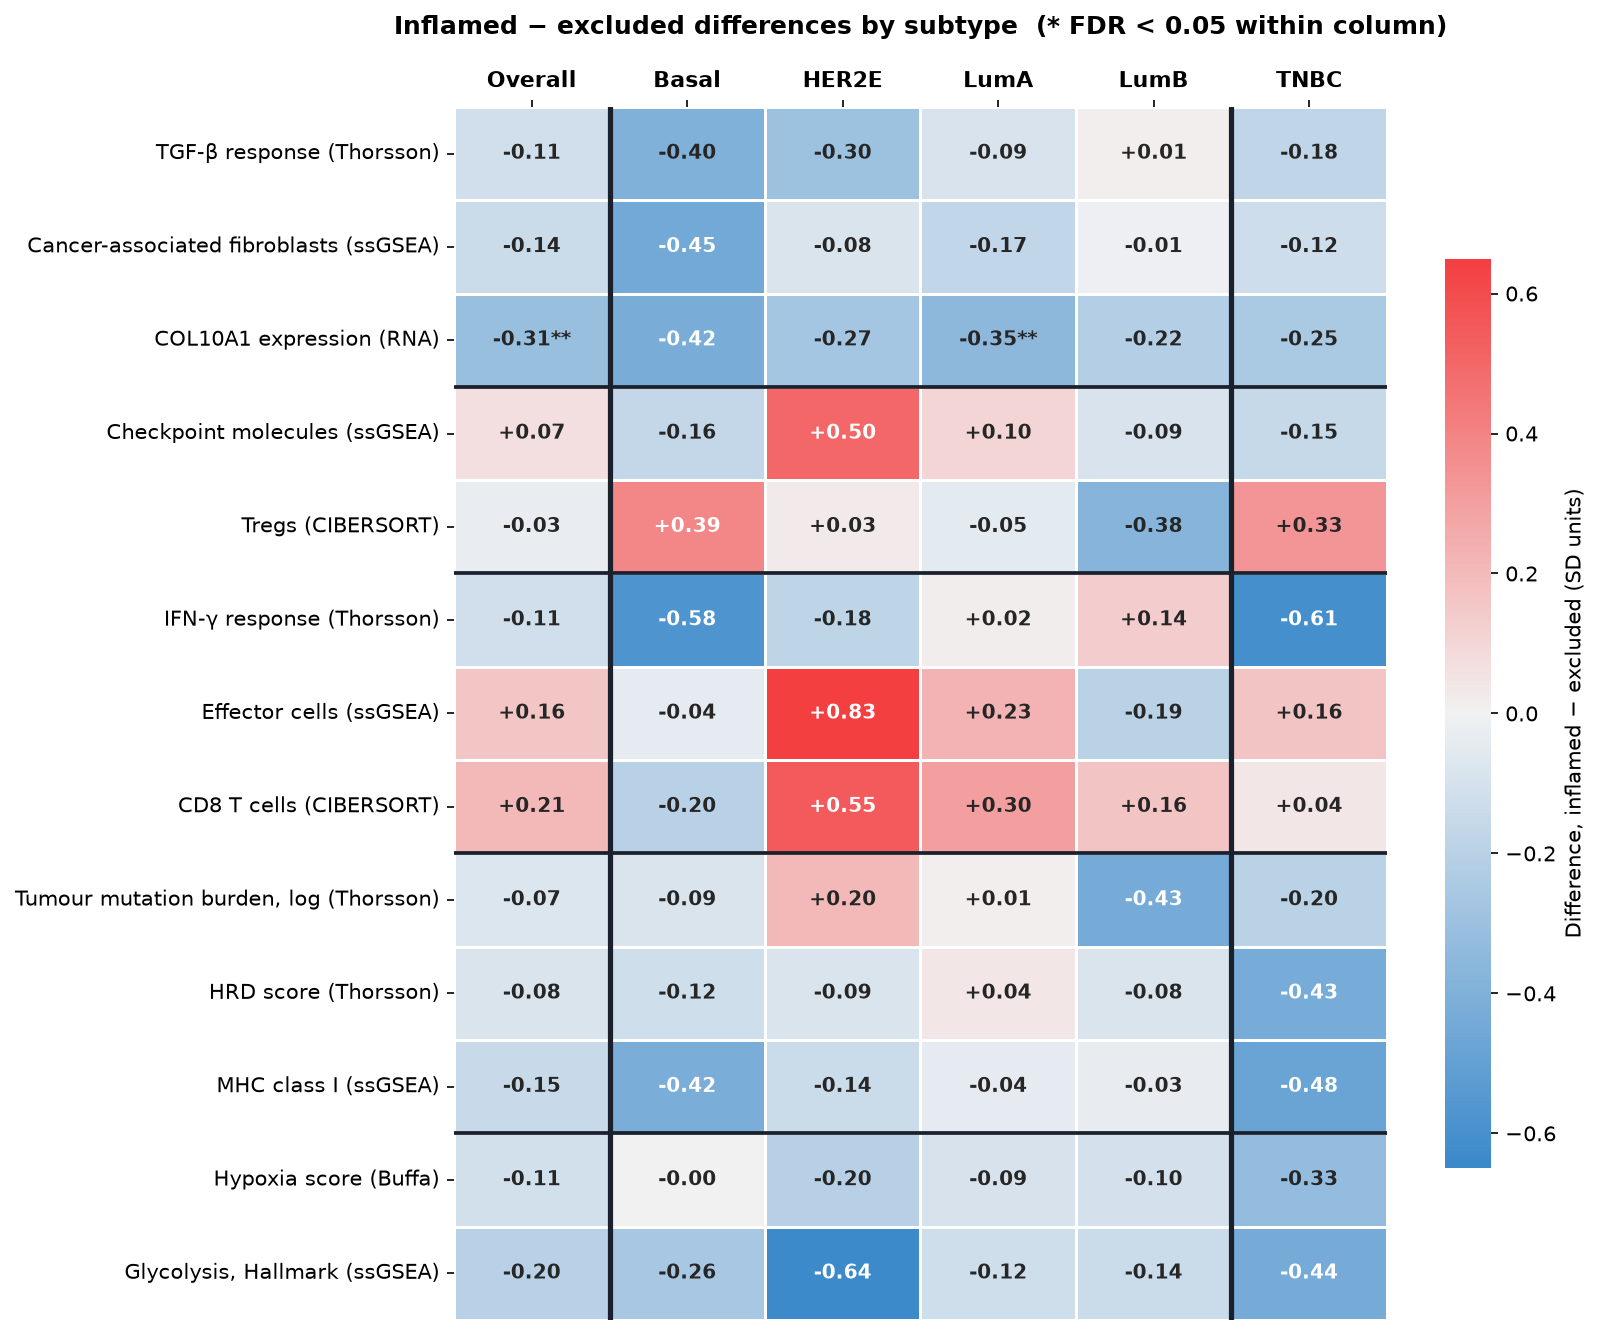

In [14]:
counts = hot[SUBTYPE].value_counts()
SUBTYPES = [s for s in (IP["subtype_strata"] or SUBTYPE_ORDER) if counts.get(s, 0) >= IP["min_stratum_size"]]
strata = {"Overall": (hot, {"categorical": [SUBTYPE], "continuous": [PURITY]})}
strata.update({s: (hot[hot[SUBTYPE] == s], {"continuous": [PURITY]}) for s in SUBTYPES})
EXTRA = {name: col for name, col in IP["extra_strata"].items() if col in hot.columns}
for name, col in EXTRA.items():
    strata[name] = (hot[hot[col] == 1], {"continuous": [PURITY]})

df_heat = pd.DataFrame([
    {"group": g, "variable": col, "label": label, "stratum": name, **fit_effect(data, col, **kwargs)}
    for g, col, label in hyp_vars for name, (data, kwargs) in strata.items()
])
df_heat = add_fdr(df_heat, by="stratum")
df_heat.to_csv(TABLES / "subtype_effects.csv", index=False)

cols = list(strata)
pivot_eff = df_heat.pivot(index="variable", columns="stratum", values="effect").reindex(
    index=[c for _, c, _ in hyp_vars], columns=cols)
pivot_q = df_heat.pivot(index="variable", columns="stratum", values="fdr").reindex(
    index=[c for _, c, _ in hyp_vars], columns=cols)


annot = np.array([["n/a" if np.isnan(e) else f"{e:+.2f}{stats.stars(q, FDR_ALPHA)}" for e, q in zip(re, rq)]
                  for re, rq in zip(pivot_eff.values, pivot_q.values)], dtype=object)

fig, ax = plt.subplots(figsize=(11, 9), dpi=150)
sns.heatmap(pivot_eff, cmap=sns.diverging_palette(245, 12, s=85, l=55, as_cmap=True), center=0,
            vmin=-0.65, vmax=0.65, annot=annot, fmt="", annot_kws={"fontsize": 9.5, "fontweight": "bold"},
            linewidths=1.2, linecolor="white",
            cbar_kws={"label": "Difference, inflamed − excluded (SD units)", "shrink": 0.75}, ax=ax)
ax.axvline(1, color="#1a202c", lw=2.5)
if EXTRA:
    ax.axvline(len(cols) - len(EXTRA), color="#1a202c", lw=2.5)
groups_plotted = [g for g, _, _ in hyp_vars]
for i in range(1, len(groups_plotted)):
    if groups_plotted[i] != groups_plotted[i - 1]:
        ax.axhline(i, color="#1a202c", lw=1.8)
ax.set_xticklabels(cols, fontsize=10.5, fontweight="bold", rotation=0)
ax.set_yticklabels([label for _, _, label in hyp_vars], fontsize=10, rotation=0)
ax.xaxis.tick_top()
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"Inflamed − excluded differences by subtype  (* FDR < {FDR_ALPHA} within column)",
             fontsize=12, fontweight="bold", pad=35)

plt.tight_layout()
fig.savefig(FIGS / "fig4_heatmap_subtypes.png", bbox_inches="tight", dpi=300)
plt.show()

## 8. Unbiased molecular screen (volcano plot)

All molecular variables (prefixes `thor_`, `cib_`, `sig_`, `expr_`, `hyp_`, `mut_`, `path_`, `aneu_`, `abs_`) with at least `min_values` values (`screen` in the configuration) are compared between phenotypes with the main model (SUBTYPE + purity):

- **Continuous variables:** OLS on the standardised variable → difference in SD units (panel A).
- **Binary variables** (mutations, pathways, arm-level alterations): logistic regression → log2 odds ratio (panel B). Mutations use only sequenced tumours (`mut_profiled == 1`); SUBTYPE levels with fewer than 30 tumours are dropped; models need ≥ 10 events in total and ≥ 3 per group.

A single FDR is computed across both panels, because they answer one question (which molecular features differ between phenotypes). Variables used to define the groups or as covariates are excluded.

In [15]:
MOLECULAR_PREFIXES = tuple(IP["screen"]["prefixes"])
EXCLUDE = set(IP["screen"]["exclude"])

screen_data = df[is_hot].copy()
if "thor_tmb" in screen_data.columns:
    screen_data["thor_tmb_log1p"] = np.log1p(screen_data["thor_tmb"].clip(lower=0))

features = [c for c in screen_data.columns
            if c.startswith(MOLECULAR_PREFIXES) and c not in EXCLUDE
            and pd.api.types.is_numeric_dtype(screen_data[c]) and screen_data[c].notna().sum() >= IP["screen"]["min_values"]]
binary_features = [c for c in features if set(screen_data[c].dropna().unique()) <= {0, 1}]
continuous_features = [c for c in features if c not in binary_features and screen_data[c].nunique() > 2]

profiled = screen_data["mut_profiled"] == 1 if "mut_profiled" in screen_data.columns else True
rows = []
for f in continuous_features:
    screen_data[f] = zscore(screen_data[f].astype(float))
    rows.append({"feature": f, "type": "continuous",
                 **fit_effect(screen_data, f, categorical=[SUBTYPE], continuous=[PURITY])})
for f in binary_features:
    data = screen_data[profiled] if f.startswith("mut_") else screen_data
    rows.append({"feature": f, "type": "binary", **fit_logit(data, f)})

screen_df = add_fdr(pd.DataFrame(rows))
screen_df["neg_log10_fdr"] = -np.log10(screen_df["fdr"].clip(lower=1e-15))
print(f"Tested: {len(continuous_features)} continuous, {len(binary_features)} binary | "
      f"significant (FDR < {FDR_ALPHA}): {(screen_df['fdr'] < FDR_ALPHA).sum()}")



screen_df["family"] = screen_df["feature"].map(assign_family)
screen_df.sort_values("p_value").to_csv(TABLES / "unbiased_molecular_screen_results.csv", index=False)
display(screen_df.nsmallest(10, "p_value")[["feature", "type", "effect", "p_value", "fdr", "n"]].round(4))

Tested: 61 continuous, 26 binary | significant (FDR < 0.05): 1


,feature,type,effect,p_value,fdr,n
31,expr_COL10A1,continuous,-0.3113,0.0003,0.0255,473
46,sig_matrix_remodeling,continuous,-0.2513,0.0034,0.1431,473
18,cib_t_cells_gamma_delta,continuous,0.2264,0.0127,0.2998,473
41,sig_hallmark_glycolysis,continuous,-0.1981,0.0141,0.2998,473
23,cib_macrophages_m1,continuous,-0.2061,0.0200,0.3399,473
15,cib_t_cells_follicular_helper,continuous,-0.2078,0.0240,0.3399,473
9,cib_t_cells_cd8,continuous,0.2051,0.0389,0.4216,473
39,sig_endothelium,continuous,0.1701,0.0427,0.4216,473
49,sig_myeloid_cells_traffic,continuous,0.1779,0.0495,0.4216,473
21,cib_monocytes,continuous,0.1925,0.0496,0.4216,473


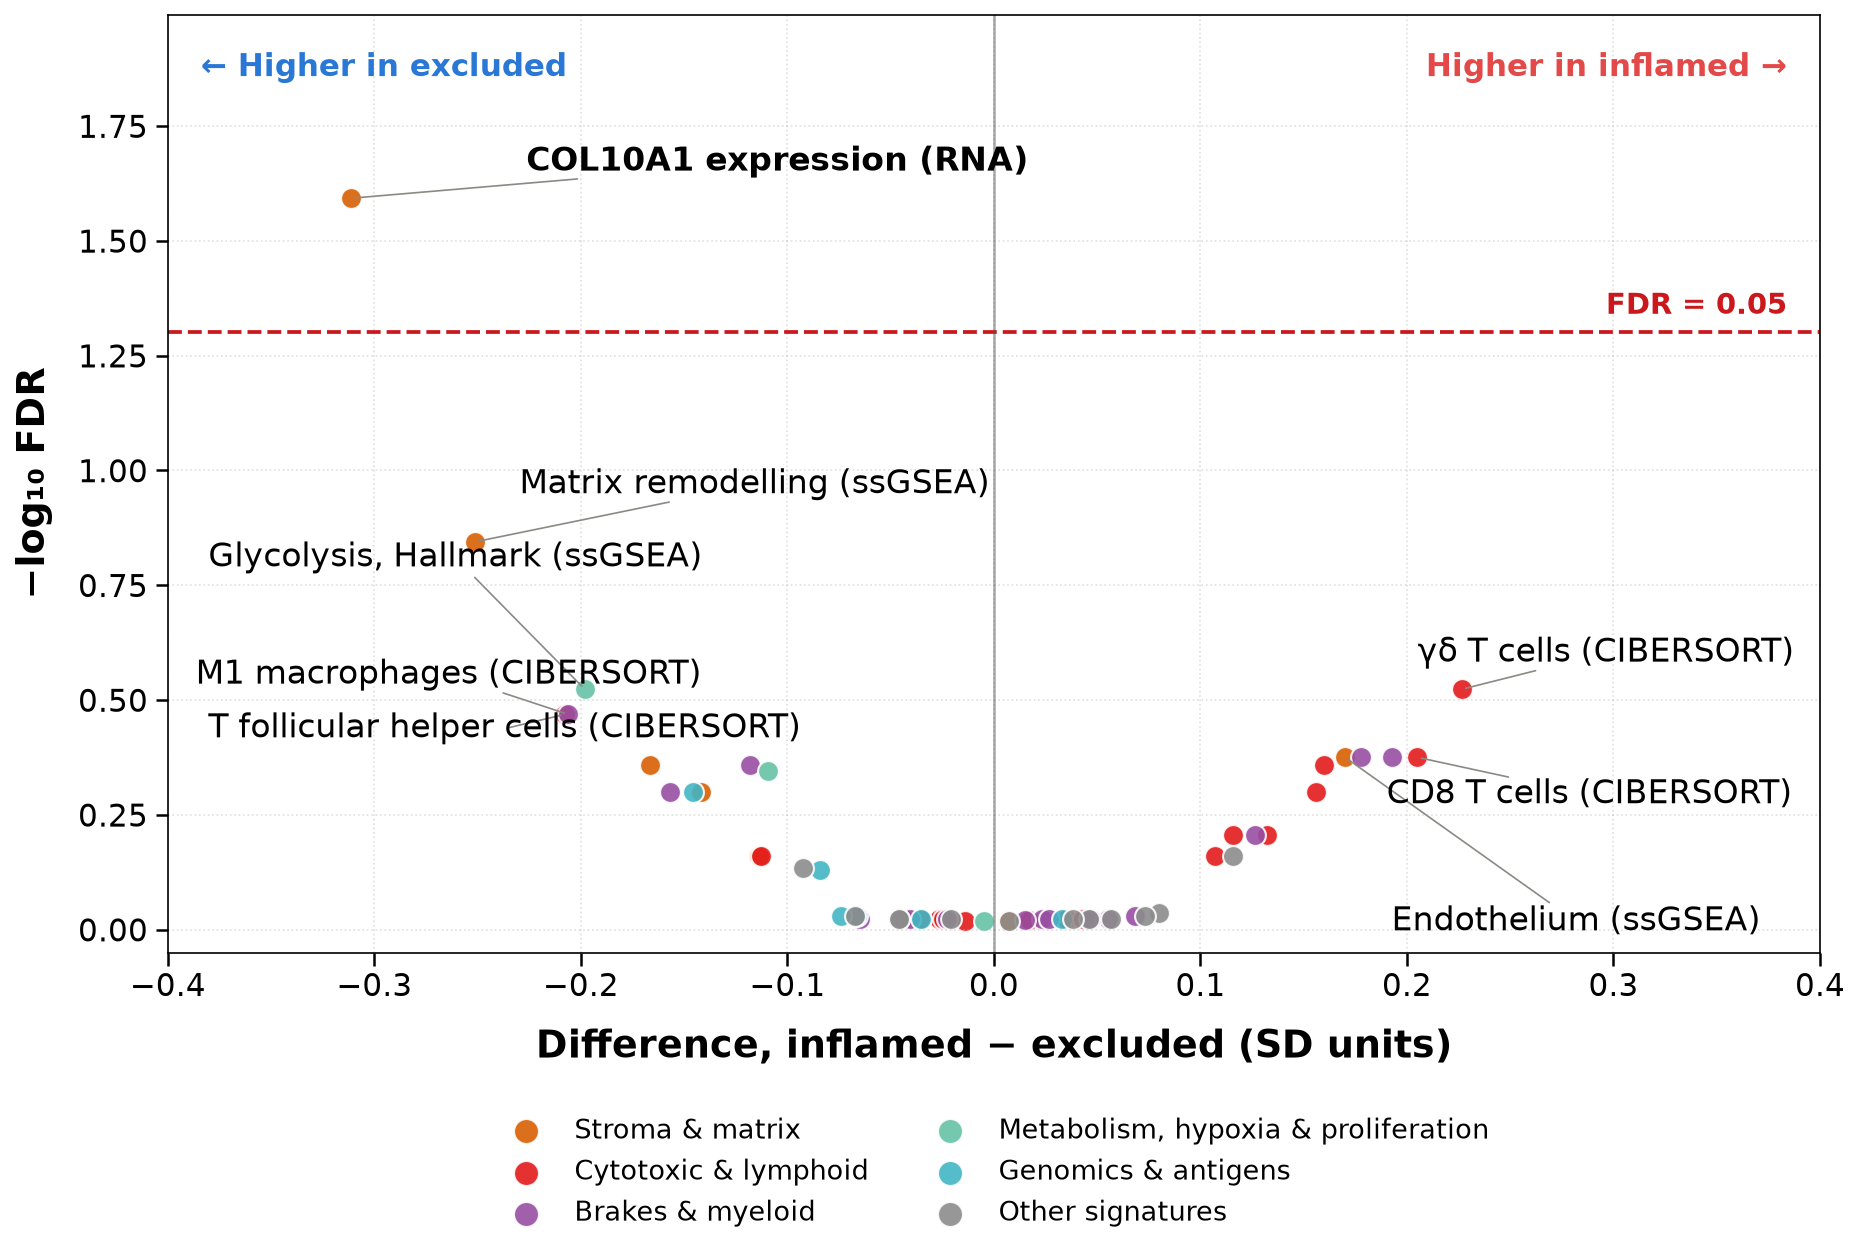

In [16]:
FAMILY_COLORS = {
    "Stroma & matrix": "#d95f02", "Cytotoxic & lymphoid": "#e41a1c", "Brakes & myeloid": "#984ea3",
    "Metabolism, hypoxia & proliferation": "#66c2a5", "Genomics & antigens": "#41b6c4",
    "Other signatures": "#8c8c8c", "Driver mutations": "#e7298a", "Oncogenic pathways": "#1f78b4",
    "Arm-level copy number": "#a6761d",
}
N_LABELS = 8          # labelled in addition to every significant variable
LABEL_FONTSIZE = 16

try:
    from adjustText import adjust_text  # optional: moves labels so they do not overlap
except ImportError:
    adjust_text = None


def volcano(data, xlabel, filename):
    d = data.dropna(subset=["effect", "fdr"]).copy()
    fig, ax = plt.subplots(figsize=(12.5, 8.5), dpi=150)
    x_lim = max(0.2, np.ceil(d["effect"].abs().max() * 12) / 10)
    y_max = max(1.8, d["neg_log10_fdr"].max() + 0.4)

    ax.axhline(-np.log10(FDR_ALPHA), color="#cb181d", ls="--", lw=1.8)
    ax.text(0.98, -np.log10(FDR_ALPHA) + 0.04, f"FDR = {FDR_ALPHA}", transform=ax.get_yaxis_transform(),
            ha="right", color="#cb181d", fontsize=14, fontweight="bold")
    ax.axvline(0, color="#525252", lw=1.2, alpha=0.5)
    for fam, color in FAMILY_COLORS.items():
        sub = d[d["family"] == fam]
        if len(sub):
            ax.scatter(sub["effect"], sub["neg_log10_fdr"], c=color, s=100, alpha=0.9,
                       edgecolors="white", linewidth=1.0, label=fam)
    ax.text(0.02, 0.96, "← Higher in excluded", transform=ax.transAxes, va="top", color=COLOR_EXCLUDED,
            fontsize=15, fontweight="bold")
    ax.text(0.98, 0.96, "Higher in inflamed →", transform=ax.transAxes, va="top", ha="right",
            color=COLOR_INFLAMED, fontsize=15, fontweight="bold")
    ax.set_xlim(-x_lim, x_lim)
    ax.set_ylim(-0.05, y_max)
    ax.set_xlabel(xlabel, fontsize=18, fontweight="bold", labelpad=12)
    ax.set_ylabel("−log₁₀ FDR", fontsize=18, fontweight="bold", labelpad=12)
    ax.tick_params(axis="both", which="major", labelsize=15, length=6, width=1.2)
    ax.grid(True, ls=":", alpha=0.4)
    ax.legend(fontsize=13, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False, markerscale=1.2)

    # Labels (with their source in parentheses): every significant variable plus the N_LABELS smallest
    # p-values; near-identical points fan out
    lab = d[(d["fdr"] < FDR_ALPHA) | d.index.isin(d.nsmallest(N_LABELS, "p_value").index)]
    x_span, y_span = np.diff(ax.get_xlim())[0], np.diff(ax.get_ylim())[0]
    cell = ((lab["effect"] / (0.02 * x_span)).round().astype(int).astype(str) + "_"
            + (lab["neg_log10_fdr"] / (0.02 * y_span)).round().astype(int).astype(str))
    fan = lab.groupby(cell).cumcount().map(lambda k: 0 if k == 0 else (1 if k % 2 else -1) * ((k + 1) // 2))
    texts = []
    for (_, r), shift in zip(lab.iterrows(), fan):
        side = 1 if r["effect"] >= 0 else -1
        texts.append(ax.text(r["effect"] + side * 0.03 * x_span, r["neg_log10_fdr"] + shift * 0.06 * y_span,
                             pretty_label(r["feature"]), fontsize=LABEL_FONTSIZE,
                             fontweight="bold" if r["fdr"] < FDR_ALPHA else "normal",
                             ha="left" if side > 0 else "right", va="center"))
    if adjust_text and texts:
        adjust_text(texts, x=d["effect"].values, y=d["neg_log10_fdr"].values, target_x=lab["effect"].values,
                    target_y=lab["neg_log10_fdr"].values, ax=ax, expand=(1.5, 2.3), force_text=(1.6, 2.2),
                    force_static=(0.5, 0.7), force_pull=(0.005, 0.005), max_move=(30, 30), time_lim=10,
                    arrowprops=dict(arrowstyle="-", color="#8a8984", lw=0.8))
    fig.tight_layout()
    fig.savefig(FIGS / filename, bbox_inches="tight", dpi=300)
    plt.show()


volcano(screen_df[screen_df["type"] == "continuous"], "Difference, inflamed − excluded (SD units)",
        "fig5a_volcano_continuous.png")

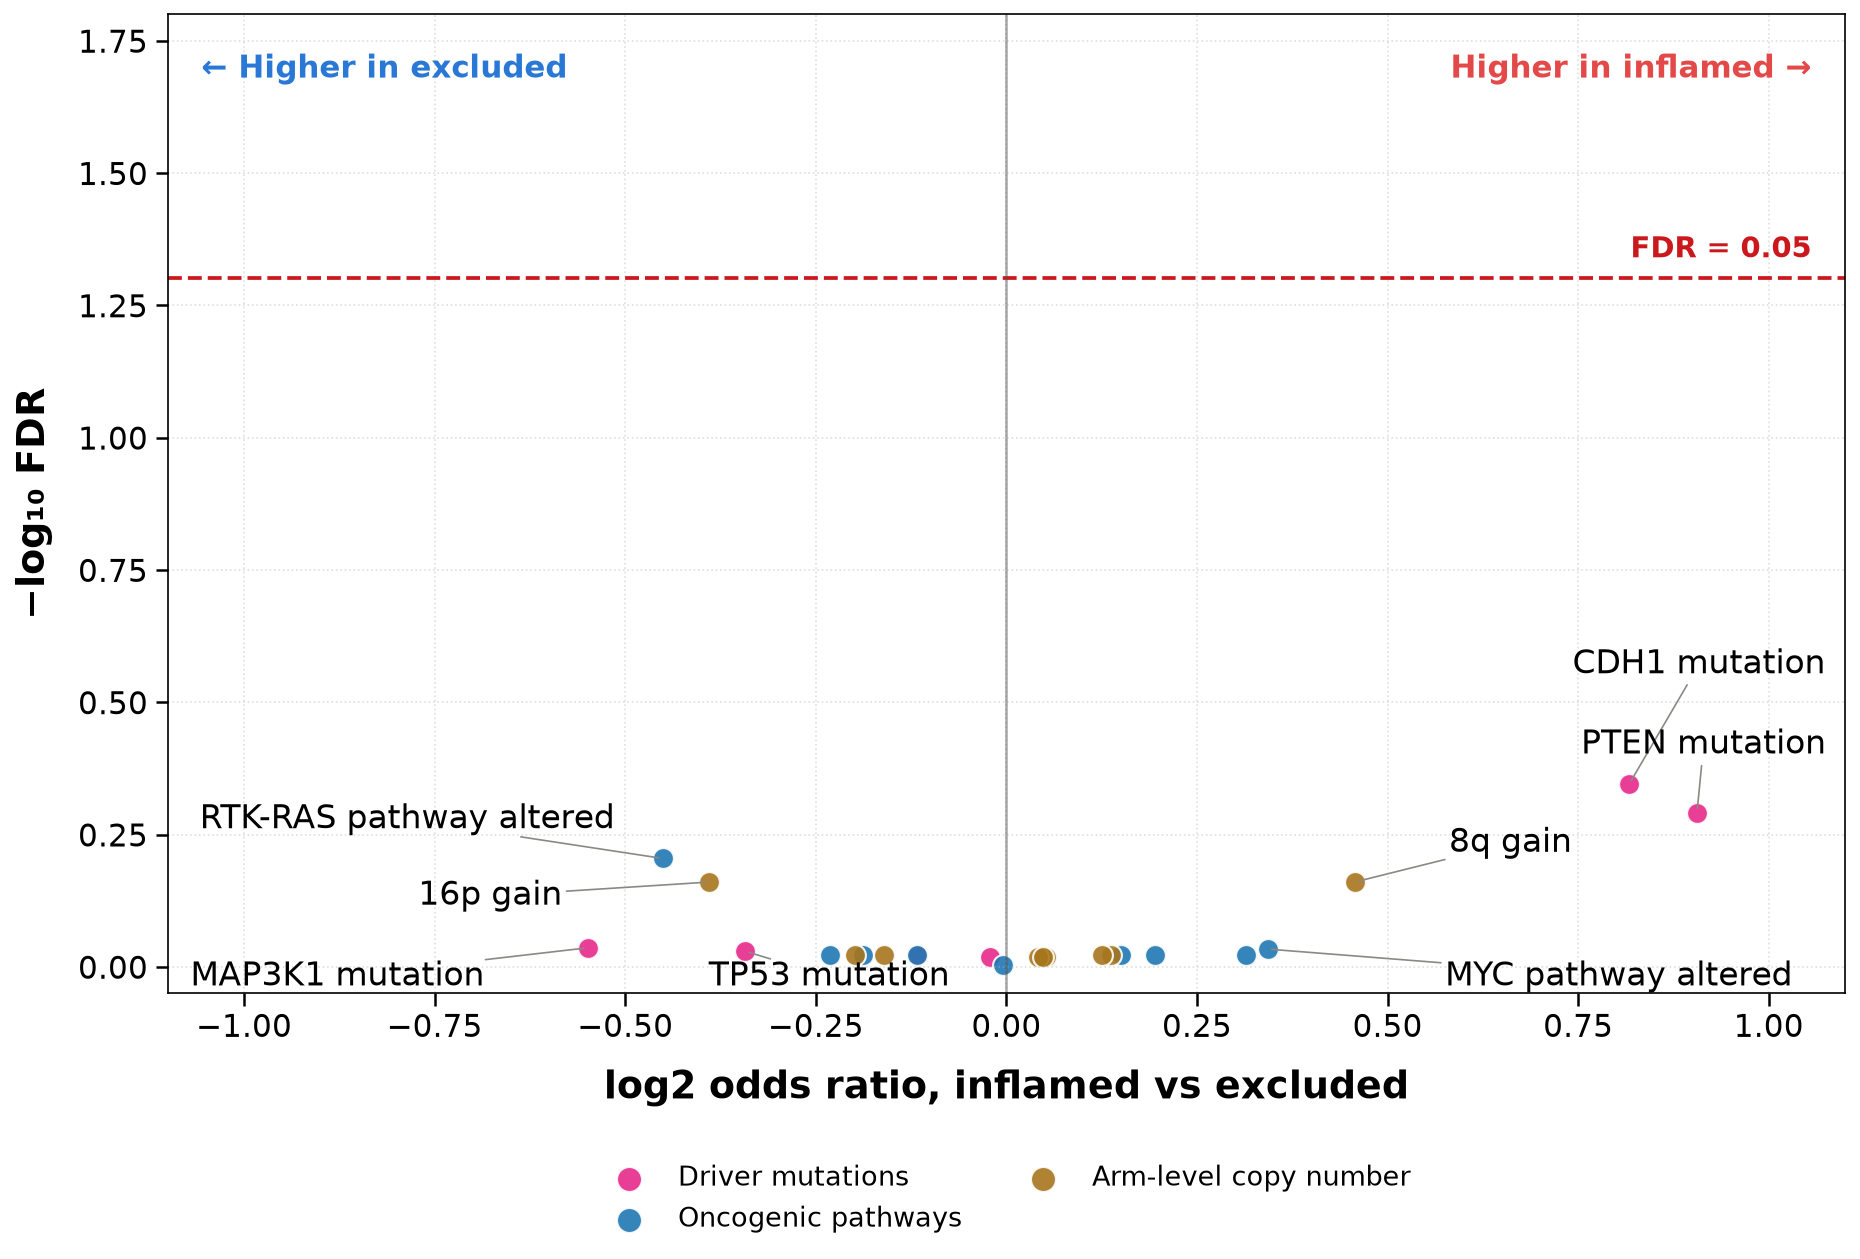

In [17]:
# Genomic alterations (binary): same layout, effect as log2 odds ratio; FDR shared with the continuous panel
volcano(screen_df[screen_df["type"] == "binary"], "log2 odds ratio, inflamed vs excluded",
        "fig5b_volcano_genomic_alterations.png")

## 9. Clinical outcome (exploratory)

Do the phenotypes relate to outcome? This section is exploratory: TCGA has short follow-up and few events in several cancers (e.g. breast).

1. **Progression-free interval (PFI)**, the endpoint recommended for TCGA breast cancer (Liu et al., *Cell* 2018), and overall survival (OS): Kaplan-Meier curves and log-rank tests.
2. **Cox models for PFI**, adjusted for age, stage, SUBTYPE and purity: one for the phenotype and one per variable listed in `outcome.cox_variables` (breast: COL10A1, per SD).
3. **Surgical margin status** by phenotype. Note: the surgical margin (tumour left at the resection edge) is not the same as the invasive margin measured on the slide.

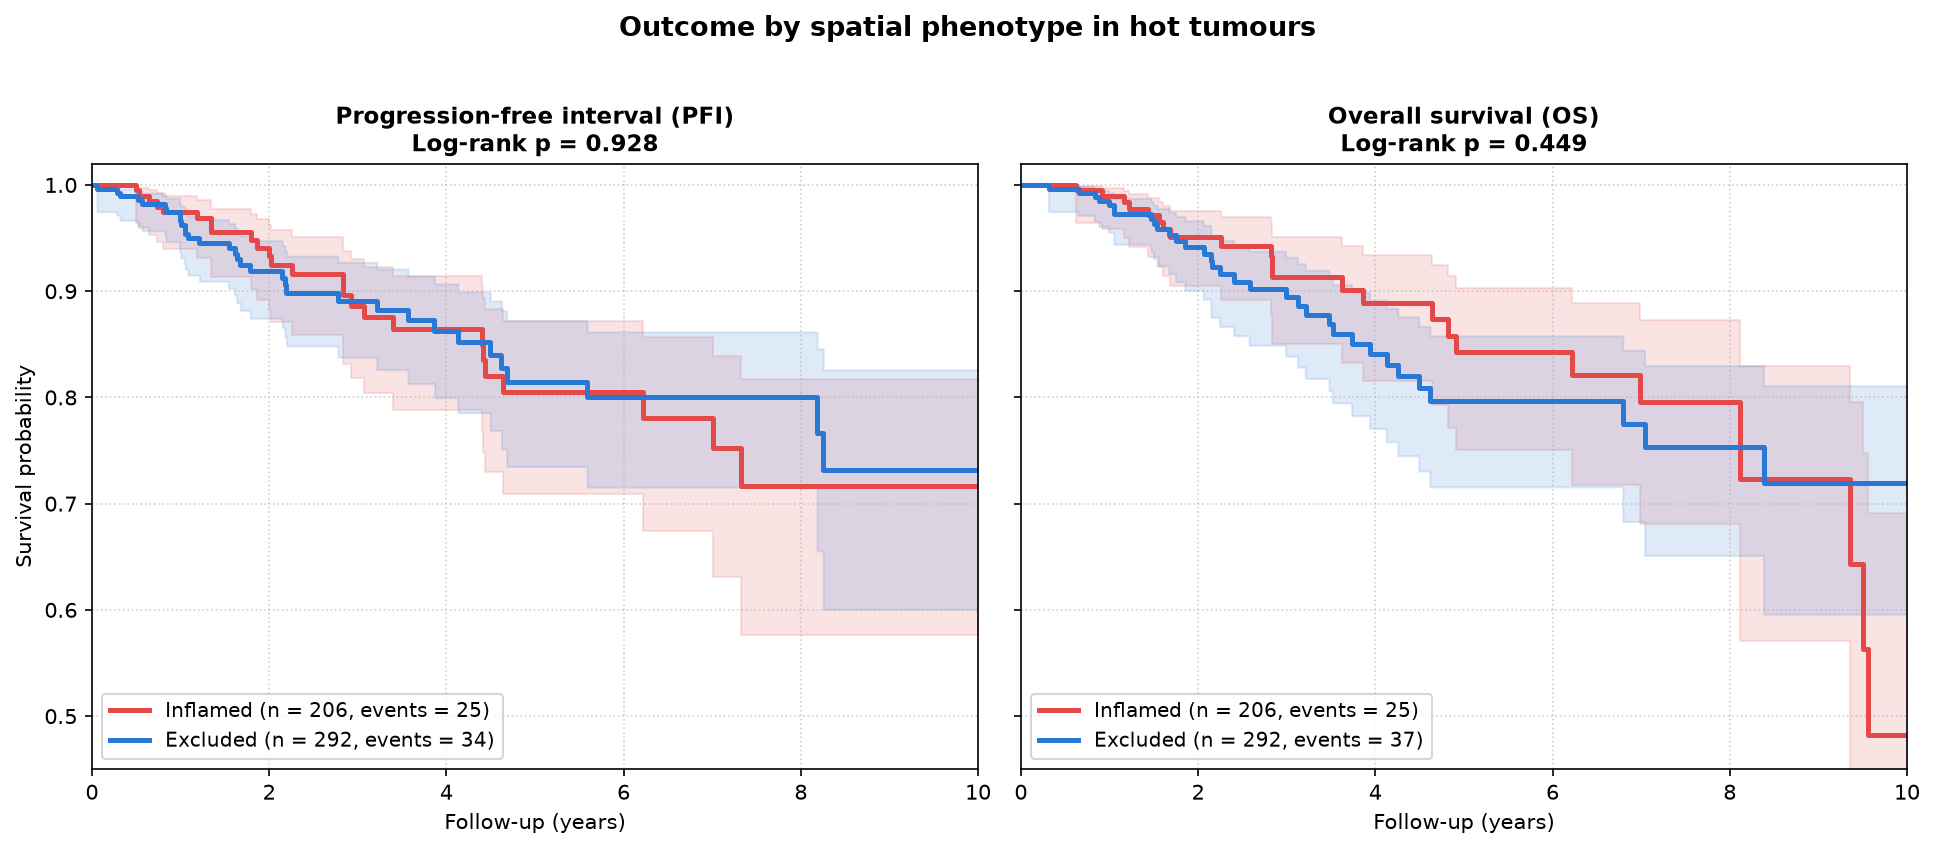

In [18]:
surv_df = df[df["spatial_phenotype"].isin(["Inflamed", "Excluded"])].copy()
surv_df["pfi_years"] = surv_df[PFI_TIME] / 365.25
surv_df["os_years"] = surv_df[OS_TIME] / 365.25

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True, dpi=150)
for ax, time_col, event_col, title in zip(axes, ["pfi_years", "os_years"], [PFI, OS],
                                           ["Progression-free interval (PFI)", "Overall survival (OS)"]):
    d = surv_df.dropna(subset=[time_col, event_col])
    inf, exc = d[d["spatial_phenotype"] == "Inflamed"], d[d["spatial_phenotype"] == "Excluded"]
    p = logrank_test(inf[time_col], exc[time_col], event_observed_A=inf[event_col],
                     event_observed_B=exc[event_col]).p_value
    for name, sub in [("Inflamed", inf), ("Excluded", exc)]:
        kmf = KaplanMeierFitter().fit(sub[time_col], event_observed=sub[event_col],
                                      label=f"{name} (n = {len(sub)}, events = {int(sub[event_col].sum())})")
        kmf.plot_survival_function(ax=ax, color=PHENOTYPE_COLORS[name], lw=2.4, ci_show=True, ci_alpha=0.15)
    ax.set_title(f"{title}\nLog-rank " + ("p < 0.001" if p < 0.001 else f"p = {p:.3f}"), fontweight="bold")
    ax.set_xlabel("Follow-up (years)")
    ax.set_xlim(0, IP["outcome"]["max_years"])
    ax.set_ylim(0.45, 1.02)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=9.5, loc="lower left")
axes[0].set_ylabel("Survival probability")
fig.suptitle("Outcome by spatial phenotype in hot tumours", fontweight="bold", y=1.02)

plt.tight_layout()
fig.savefig(FIGS / "fig6_kaplan_meier_pfi_os.png", bbox_inches="tight", dpi=300)
plt.show()

In [19]:
COX_VARS = [v for v in IP["outcome"]["cox_variables"] if v in surv_df.columns]
cox_sub = surv_df[["pfi_years", PFI, "phenotype_binary", AGE, STAGE, SUBTYPE, PURITY, *COX_VARS]].dropna()
cox_sub = cox_sub[cox_sub["pfi_years"] > 0].copy()
cox_sub["age_std"], cox_sub["purity_std"] = zscore(cox_sub[AGE]), zscore(cox_sub[PURITY])
terms = [("Spatial phenotype (inflamed vs. excluded)", "phenotype_binary")]
for v in COX_VARS:
    cox_sub[f"{v}_std"] = zscore(cox_sub[v])
    terms.append((f"{pretty_label(v)} (per SD)", f"{v}_std"))

covariates = f"age_std + C({STAGE}) + C({SUBTYPE}) + purity_std"
cox_rows = []
for label, term in terms:
    # Small ridge penalty for numerical stability with few events; it shrinks HRs slightly towards 1
    cph = CoxPHFitter(penalizer=IP["outcome"]["cox_penalizer"]).fit(
        cox_sub, duration_col="pfi_years", event_col=PFI, formula=f"{term} + {covariates}")
    s = cph.summary.loc[term]
    cox_rows.append({"endpoint": "PFI", "model": label, "hazard_ratio": s["exp(coef)"],
                     "ci_lower": s["exp(coef) lower 95%"], "ci_upper": s["exp(coef) upper 95%"],
                     "p_value": s["p"], "n": len(cox_sub), "events": int(cox_sub[PFI].sum())})

cox_results_df = pd.DataFrame(cox_rows)
cox_results_df.to_csv(TABLES / "clinical_survival_cox_models.csv", index=False)
display(cox_results_df.round(3))

,endpoint,model,hazard_ratio,ci_lower,ci_upper,p_value,n,events
0,PFI,Spatial phenotype (inflamed vs. excluded),0.984,0.653,1.483,0.937,453,53
1,PFI,COL10A1 expression (RNA) (per SD),1.020,0.829,1.254,0.853,453,53


In [20]:
margin_df = surv_df.dropna(subset=[MARGIN_STATUS])
table = pd.crosstab(margin_df["spatial_phenotype"], margin_df[MARGIN_STATUS])

print("Surgical margin status by phenotype (counts):")
display(table)
print("Row %:")
display((pd.crosstab(margin_df["spatial_phenotype"], margin_df[MARGIN_STATUS], normalize="index") * 100).round(1))
chi2, p_margin, _, _ = chi2_contingency(table)
print(f"Chi-square test: chi2 = {chi2:.2f}, p = {p_margin:.3f}")

Surgical margin status by phenotype (counts):


clin_margin_status,Close,Negative,Positive
spatial_phenotype,,,
Excluded,6,264,4
Inflamed,5,179,13


Row %:


clin_margin_status,Close,Negative,Positive
spatial_phenotype,,,
Excluded,2.2,96.4,1.5
Inflamed,2.5,90.9,6.6


Chi-square test: chi2 = 8.81, p = 0.012


## 10. Export the patient-level phenotype table

Saved in `<data>/processed/` for the following notebooks (e.g. the TLS analysis of notebook 05). It holds patient-level values and must not be committed to Git or shared outside the project.

In [21]:
export_cols = ["patient", "TCGA_CASE_ID", "spatial_phenotype", "spatial_index_wtr", "is_hot", "phenotype_binary",
               SUBTYPE, *IP["extra_strata"].values(), PURITY, LEUKOCYTE_FRACTION, "img_lymph_total_mm2",
               PFI, PFI_TIME, OS, OS_TIME, MARGIN_STATUS]
out = df[[c for c in dict.fromkeys(export_cols) if c in df.columns]]
out.to_parquet(P["spatial_phenotypes"], index=False)
print(f"Exported {len(out)} patients to {P['spatial_phenotypes'].name}")

Exported 1025 patients to spatial_phenotypes_breast_cancer.parquet
